# Przegląd wykorzystania OBV

## Co mamy?

W danych eventowych jest do wykorzystania 7 kolumn:
- obv_for_after
- obv_for_before
- obv_for_net
- obv_against_after
- obv_against_before
- obv_against_net
- obv_total_net

In [1]:
from get_data.get_data import get_merged_events
from sequences.which_sector import *
from sequences.get_sequences import *

match = 3836322 # Jagiellonia vs Lech
def_areas_x = 12
def_areas_y = 8

events_types_to_analize = ['passes', 'carrys', 'ball_receipts', 'ball_recoverys', 'duels', 'dribbles', 'blocks', 'clearances', 
'dispossesseds', 'errors', 'foul_committeds', 'foul_wons', 'half_ends', 'injury_stoppages', 'interceptions', 'miscontrols', 'shots']

events = get_merged_events(events_types_to_analize, match)

In [2]:
from dataframe_modify.add_positions import add_positions
from dataframe_modify.swap_perspective import swap_y
from dataframe_modify.swap_perspective import generalize_perspective
from dataframe_modify.grid_areas import add_grid_areas

start_team = events['possession_team'][0]

events = add_positions(events)
events = generalize_perspective(events, start_team)
events = swap_y(events)
events = add_grid_areas(events)

In [3]:
from sequences.get_sequences import get_sequences_by_possession

sequences = get_sequences_by_possession(events)

seq_50 = sequences[58]
seq_50.to_csv('sequence_50_goal.csv', encoding='utf-8', index=False)

In [4]:
seq_58 = sequences[83]
# seq_58 = seq_58[seq_58['possession']==113]
seq_58.to_csv('sequence_58_missed.csv', encoding='utf-8', index=False)

In [5]:
seq_91 = sequences[123]
# seq_91 = seq_91[seq_91['possession']==169]
seq_91.to_csv('sequence_91_goal.csv', encoding='utf-8', index=False)

In [6]:
seq_46 = sequences[55]
# seq_46 = seq_46[seq_46['possession']==74]
seq_46.to_csv('sequence_46_goal_JAG.csv', encoding='utf-8', index=False)

## Przygotowanie wizualizacji

Team: Lech Poznan
1: Michał Skóraś (Foul Committed) <00:38:34.252>
2: Wojciech Łaski (Foul Won) <00:38:34.252>
3: Bojan Nastić (Pass) <00:38:36.608>
4: Jesús Imaz Ballesté (Ball Receipt*) <00:38:37.894>
5: Pedro Miguel Braga Rebocho (Pass) <00:38:37.894>
6: Michał Skóraś (Ball Receipt*) <00:38:40.143>
6: Michał Skóraś (Carry) <00:38:40.143>
6: Michał Skóraś (Pass) <00:38:41.461>
7: Pedro Miguel Braga Rebocho (Ball Receipt*) <00:38:44.241>
7: Pedro Miguel Braga Rebocho (Carry) <00:38:44.241>
7: Pedro Miguel Braga Rebocho (Pass) <00:38:51.114>
8: Radosław Murawski (Ball Receipt*) <00:38:52.428>
8: Radosław Murawski (Carry) <00:38:52.428>
8: Radosław Murawski (Pass) <00:38:53.515>
9: Alan Czerwiński (Ball Receipt*) <00:38:55.773>
9: Alan Czerwiński (Carry) <00:38:55.773>
9: Alan Czerwiński (Pass) <00:39:00.831>
10: Radosław Murawski (Ball Receipt*) <00:39:01.845>
10: Radosław Murawski (Carry) <00:39:01.845>
10: Radosław Murawski (Pass) <00:39:02.676>
11: Heorhii Tsitaishvili (Ball Receipt

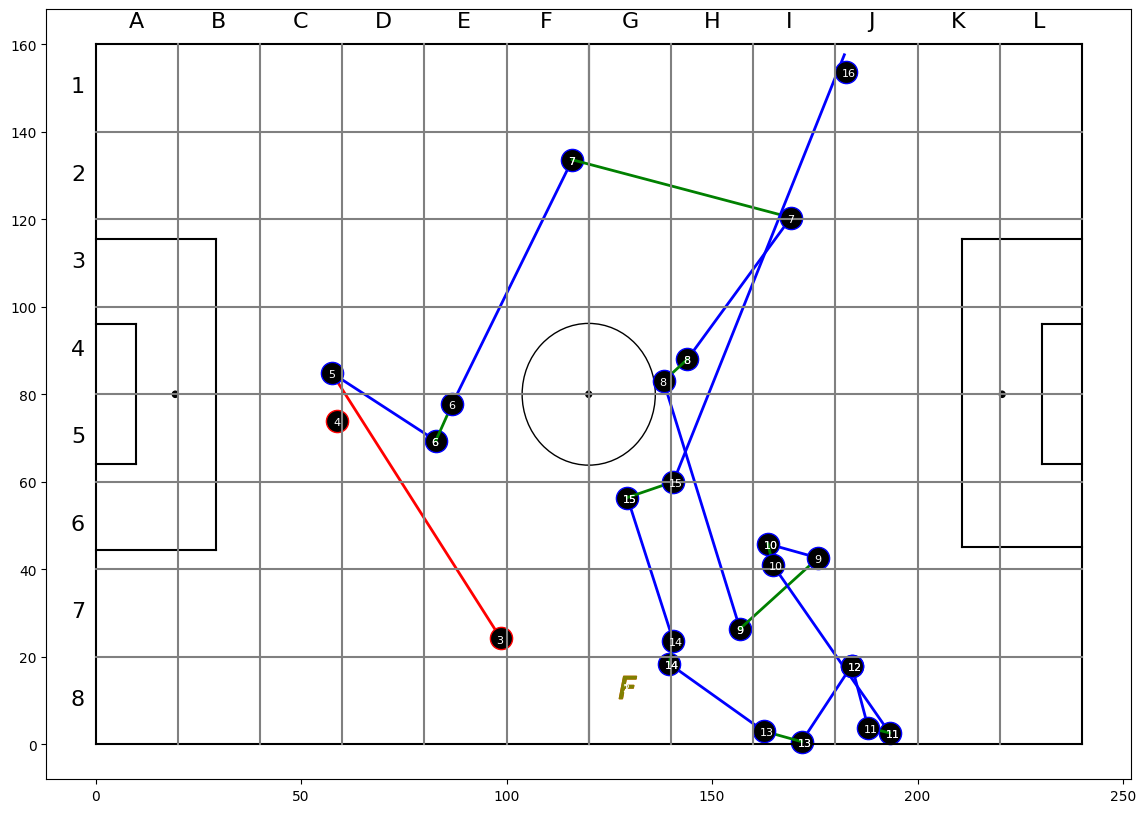

In [7]:
from draw.draw_sequences import draw_events_sequence

draw_events_sequence(seq_50, start_team, 12, 8, scale=2)

Team: Jagiellonia Białystok
1: Mateusz Skrzypczak (Pass) <00:00:28.287>
2: Tomáš Přikryl (Ball Receipt*) <00:00:29.256>
2: Tomáš Přikryl (Pass) <00:00:29.256>
3: Mateusz Skrzypczak (Ball Receipt*) <00:00:31.364>
3: Mateusz Skrzypczak (Carry) <00:00:31.364>
3: Mateusz Skrzypczak (Pass) <00:00:32.756>
4: Wojciech Łaski (Ball Receipt*) <00:00:33.499>
5: Michał Skóraś (Interception) <00:00:33.499>


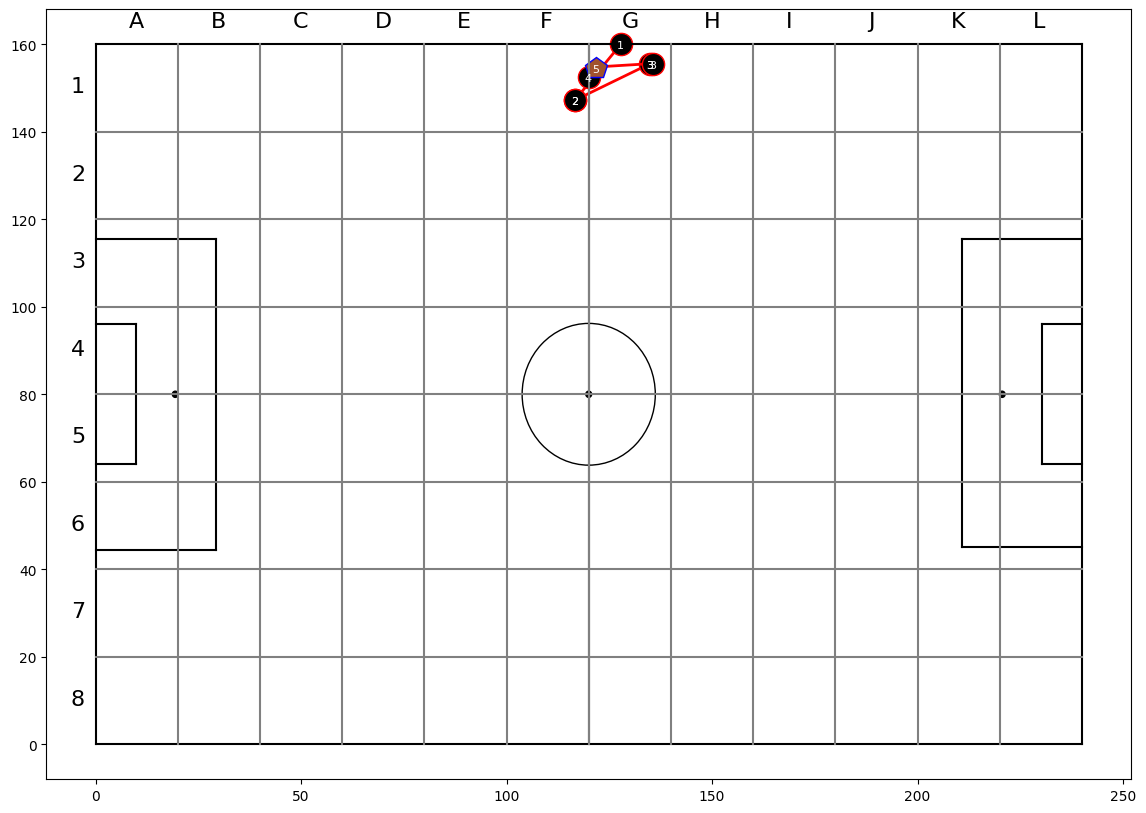

In [8]:
draw_events_sequence(seq_58, start_team, 12, 8, scale=2)

Team: Jagiellonia Białystok
1: Zlatan Alomerović (Ball Recovery) <00:27:04.211>
1: Zlatan Alomerović (Carry) <00:27:04.211>
1: Zlatan Alomerović (Pass) <00:27:13.903>
2: Fedor Černych (Ball Receipt*) <00:27:16.271>
2: Fedor Černych (Carry) <00:27:16.271>
2: Fedor Černych (Pass) <00:27:17.397>
3: Mateusz Skrzypczak (Ball Receipt*) <00:27:19.237>
3: Mateusz Skrzypczak (Carry) <00:27:19.237>
3: Mateusz Skrzypczak (Pass) <00:27:23.122>
4: Zlatan Alomerović (Ball Receipt*) <00:27:25.449>
4: Zlatan Alomerović (Carry) <00:27:25.449>
4: Zlatan Alomerović (Pass) <00:27:26.735>
5: Mateusz Skrzypczak (Ball Receipt*) <00:27:28.215>
5: Mateusz Skrzypczak (Carry) <00:27:28.215>


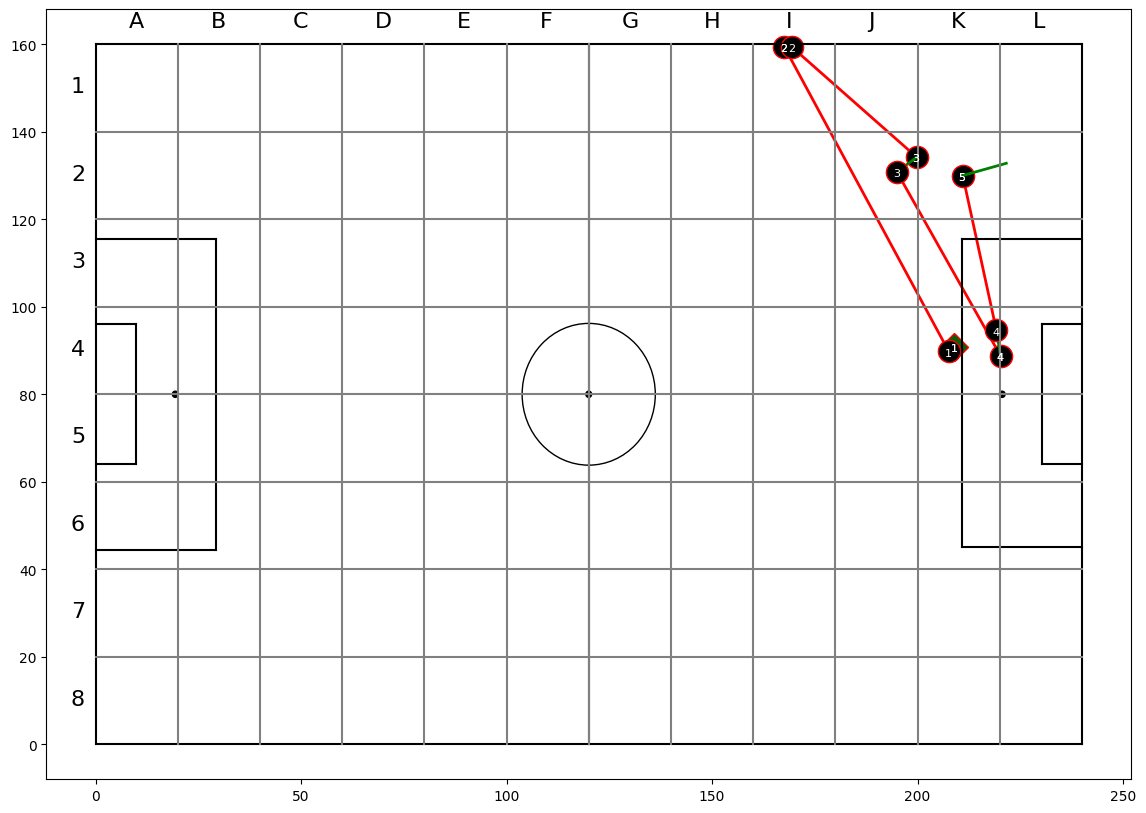

In [9]:
draw_events_sequence(seq_91, start_team, 12, 8, scale=2)

Team: Lech Poznan
1: Bogdan Ionuț Țîru (Foul Committed) <00:35:57.112>
2: Michał Skóraś (Foul Won) <00:35:57.112>
3: Alan Czerwiński (Pass) <00:36:40.602>
4: Miłosz Matysik (Clearance) <00:36:42.407>
5: Heorhii Tsitaishvili (Pass) <00:36:46.109>
6: Jesper Karlström (Ball Receipt*) <00:36:48.105>
6: Jesper Karlström (Carry) <00:36:48.105>
6: Jesper Karlström (Pass) <00:36:49.244>


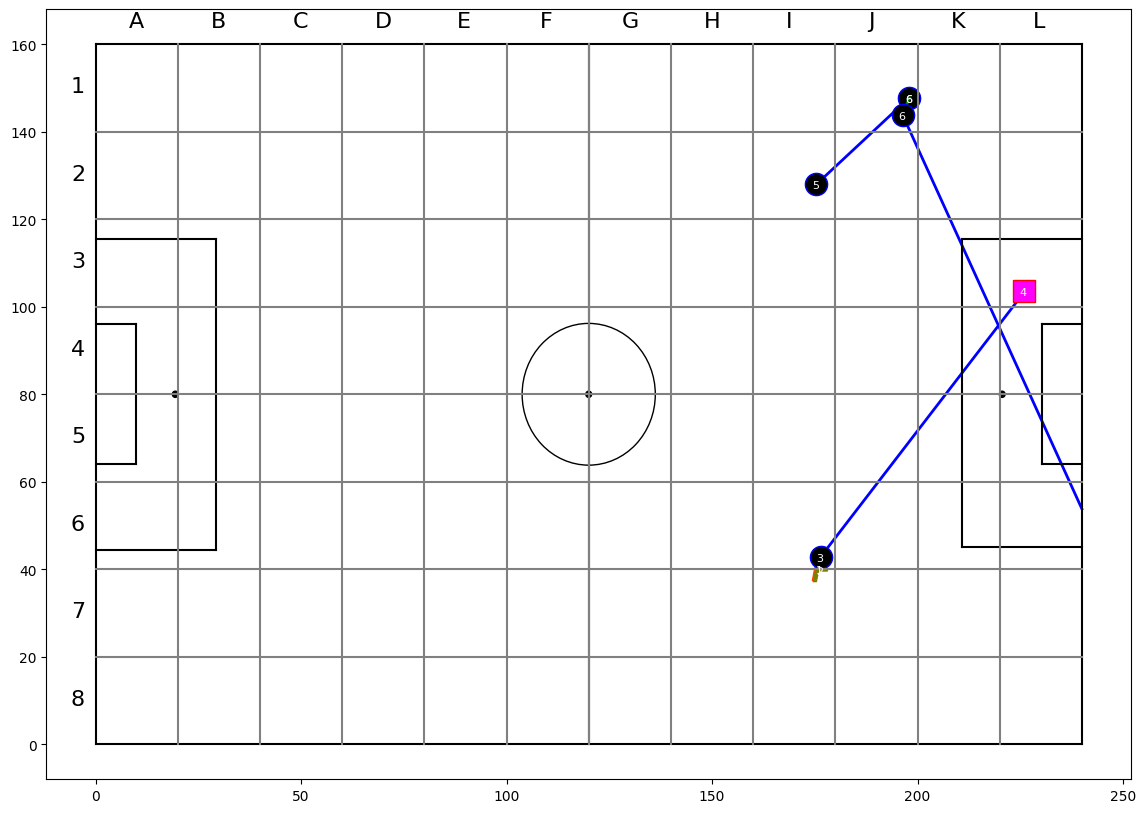

In [10]:
draw_events_sequence(seq_46, start_team, 12, 8, scale=2)